# Designing an Exercise Path for Learning Gain in Limited Time
**HCI 26, Milestone 3: UI Optimization. Group 3, topic "When is help actually helpful?"**

A student who wants to practice has limited time and a bank of exercises. Which exercises should they do, and in which order? This notebook formulates that choice as an **integer program** and solves it with Gurobi. It runs on its own. The same model (the function `solve_path` below) is what our app uses to propose practice exercises, and it is the optimized variant of the Milestone 4 A/B test.

**Everything numeric here is made up.** The exercise bank, the simulated students and the assumed learning rules are our own constructions. We say so again where it matters.

Contents: 1 The design problem, 2 Data, 3 Student model, 4 Optimization model, 5 Solving an example, 6 Reference designs, 7 What-if analysis, 8 Checks, 9 Limits.

# 1. The design problem
***
**Decision.** Which exercises should the student practice, and in which order, in the time they have?

**Why it matters.** Our need-finding (Milestone 1) found that students under time pressure still need to learn and not only finish, that they need room to struggle before help arrives, and that they need to understand an idea well enough to solve similar problems alone. Practice supports all three, but only if the exercises are well chosen. An exercise that is too easy teaches nothing. One that is too hard frustrates and invites handing the problem to someone else, an AI included. What is right changes as the student practices (the level rises), a student who just failed an exercise needs a related one, and two near-identical exercises waste time. A simple rule (for example "easy to hard") cannot trade all of this off.

**Design variables.** For each position `t` of the path, which exercise is placed there (or none).

**Objective.** Maximize the learning gained over the session, with penalties for near-duplicates and for exercises that are not from the student's own course, and a bonus for exercises related to what the student just failed.

**Setting.** The plan changes after every answer, because the student's level changes, so we solve again each time and apply the first step. In this notebook we solve one plan at a time, independently of any app. The brief does not ask for real-time solving.

In [1]:
# Optional: install the dependencies (see requirements.txt)
# !pip install -r requirements.txt

import json, math, itertools, random
import numpy as np
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB
%matplotlib inline
print('Gurobi', '.'.join(map(str, gp.gurobi.version())))

Gurobi 14.0.0


# 2. Data: the exercise bank
***
The optimization takes a **bank of exercises** as input. The bank can be changed without touching the model, and it is meant to be built for each student:

- **The student's own exercises.** The student provides exercises from their course material. A language model splits an exercise sheet into single exercises and gives each a topic, a difficulty, an estimated time and knowledge tags.
- **Generated exercises.** A language model adds exercises to fill gaps, so the optimizer has real choices in every topic. They carry the source flag `ai`, are discouraged by the penalty $\lambda_{\text{gen}}$ (the student's own exercises come first), and should have answers that can be checked automatically, because a wrong answer key would mislead both the student and the planner.

The model needs exactly five things for each exercise: a **topic**, a **difficulty** $d$ from 1 to 10, an **estimated time** in minutes, a **source** (`up` = from the student's course material, `ai` = generated) and a set of **knowledge elements** (tags such as `chain`, `product`). The elements are used only to measure how similar two exercises are: the **similarity** is the Jaccard overlap of their tags, a stand-in for embeddings plus a language-model rating. A bank for another course (or another kind of exercise) only has to provide these fields.

**The bank used here is only an example** of what such a bank looks like: the bank in the next cell has 100 exercises on five Calculus topics from a derivatives lecture, 39 of them marked as generated. We wrote it ourselves, so difficulty, time and tags are our estimates and not measurements. In a real use they would be estimates by a language model, which would have to be cited.

In [2]:
import json, math, itertools, random
import numpy as np
import gurobipy as gp
from gurobipy import GRB

sig = lambda x: 1 / (1 + math.exp(-x))
logit = lambda p: math.log(p / (1 - p))
clamp = lambda x, a, b: min(b, max(a, x))

# The exercise bank (an example, see above): one entry per exercise. The same data is also saved in exercise_bank.json.
BANK_JSON = '''[
  {"id":"b1","topic":"basic","d":2,"min":0.75,"src":"up","el":["power"]},
  {"id":"b2","topic":"basic","d":3,"min":1,"src":"up","el":["power","sum","cm","cubic"]},
  {"id":"b3","topic":"basic","d":4,"min":1.25,"src":"up","el":["power","sum","cm","fraction-coef"]},
  {"id":"b4","topic":"basic","d":5,"min":1.25,"src":"ai","el":["power","sum","cm","odd-powers","three-terms"]},
  {"id":"q1","topic":"pq","d":4,"min":1.25,"src":"up","el":["power","product"]},
  {"id":"q2","topic":"pq","d":5,"min":1.5,"src":"up","el":["power","product","sum","linear"]},
  {"id":"q3","topic":"pq","d":6,"min":1.75,"src":"ai","el":["power","quotient"]},
  {"id":"q4","topic":"pq","d":7,"min":2,"src":"ai","el":["power","quotient","sum"]},
  {"id":"c0","topic":"chain","d":2,"min":0.75,"src":"up","el":["power","chain","linear-inside"]},
  {"id":"c1","topic":"chain","d":4,"min":1,"src":"up","el":["power","chain","linear-inside","sum"]},
  {"id":"c2","topic":"chain","d":5,"min":1.25,"src":"up","el":["power","chain","quad-inside"]},
  {"id":"c3","topic":"chain","d":6,"min":1.5,"src":"ai","el":["power","chain","quad-inside","cm"]},
  {"id":"c4","topic":"chain","d":8,"min":2,"src":"ai","el":["power","chain","product"]},
  {"id":"c5","topic":"chain","d":7,"min":1.75,"src":"ai","el":["power","chain","cubic-inside","sum"]},
  {"id":"t1","topic":"tangent","d":3,"min":0.75,"src":"up","el":["power","sum","tangent"]},
  {"id":"t2","topic":"tangent","d":5,"min":1.5,"src":"ai","el":["power","chain","tangent"]},
  {"id":"t3","topic":"tangent","d":6,"min":1.25,"src":"up","el":["power","sum","tangent","cubic"]},
  {"id":"o0","topic":"optim","d":2,"min":0.75,"src":"up","el":["power","sum","critical"]},
  {"id":"o1","topic":"optim","d":4,"min":1,"src":"up","el":["power","sum","critical","constant"]},
  {"id":"o2","topic":"optim","d":6,"min":1.5,"src":"up","el":["power","sum","critical","cubic"]},
  {"id":"o3","topic":"optim","d":5,"min":1.25,"src":"ai","el":["power","critical"]},
  {"id":"b5","topic":"basic","d":4,"min":1,"src":"up","el":["power","sum","cm","odd-powers"]},
  {"id":"b6","topic":"basic","d":3,"min":0.75,"src":"up","el":["power","sum","even-powers"]},
  {"id":"b7","topic":"basic","d":5,"min":1.25,"src":"ai","el":["power","sum","cm","constant"]},
  {"id":"q5","topic":"pq","d":3,"min":1,"src":"up","el":["product","linear"]},
  {"id":"q6","topic":"pq","d":5,"min":1.25,"src":"ai","el":["power","product","cm"]},
  {"id":"q7","topic":"pq","d":6,"min":1.5,"src":"ai","el":["quotient","power","quad-num"]},
  {"id":"q8","topic":"pq","d":5,"min":1.25,"src":"up","el":["quotient","linear"]},
  {"id":"c6","topic":"chain","d":3,"min":1,"src":"up","el":["power","chain","linear-inside"]},
  {"id":"c7","topic":"chain","d":4,"min":1,"src":"up","el":["power","chain","quad-inside"]},
  {"id":"c8","topic":"chain","d":4,"min":1,"src":"ai","el":["power","chain","linear-inside"]},
  {"id":"c9","topic":"chain","d":6,"min":1.25,"src":"up","el":["power","chain","cubic-inside"]},
  {"id":"t4","topic":"tangent","d":2,"min":0.75,"src":"up","el":["power","sum","tangent"]},
  {"id":"t5","topic":"tangent","d":4,"min":1,"src":"up","el":["power","sum","tangent","cubic"]},
  {"id":"t6","topic":"tangent","d":5,"min":1.25,"src":"ai","el":["power","sum","tangent","quartic"]},
  {"id":"o4","topic":"optim","d":3,"min":0.75,"src":"up","el":["power","sum","critical"]},
  {"id":"o5","topic":"optim","d":5,"min":1.25,"src":"ai","el":["power","sum","critical","coef"]},
  {"id":"b8","topic":"basic","d":2,"min":0.75,"src":"up","el":["quartic","terms1","cm"]},
  {"id":"b9","topic":"basic","d":2,"min":0.75,"src":"up","el":["linear","terms2"]},
  {"id":"b10","topic":"basic","d":3,"min":1,"src":"up","el":["cubic","terms2","cm"]},
  {"id":"b11","topic":"basic","d":3,"min":1,"src":"ai","el":["linear","terms3","cm","constant"]},
  {"id":"b12","topic":"basic","d":4,"min":1,"src":"up","el":["quintic","terms3","cm"]},
  {"id":"b13","topic":"basic","d":4,"min":1.25,"src":"up","el":["cubic","terms3","cm"]},
  {"id":"b14","topic":"basic","d":5,"min":1.25,"src":"ai","el":["linear","terms4","cm"]},
  {"id":"b15","topic":"basic","d":6,"min":1.5,"src":"up","el":["linear","terms4","cm"]},
  {"id":"b16","topic":"basic","d":6,"min":1.5,"src":"ai","el":["quartic","terms5","cm","constant"]},
  {"id":"b17","topic":"basic","d":7,"min":1.75,"src":"ai","el":["linear","terms5","cm"]},
  {"id":"b18","topic":"basic","d":3,"min":1,"src":"up","el":["quadratic","terms3","cm","constant"]},
  {"id":"q9","topic":"pq","d":3,"min":1,"src":"up","el":["linear","terms4","constant","product"]},
  {"id":"q10","topic":"pq","d":4,"min":1.25,"src":"up","el":["quadratic","terms4","cm","constant","product"]},
  {"id":"q11","topic":"pq","d":4,"min":1.25,"src":"ai","el":["quadratic","terms3","constant","product"]},
  {"id":"q12","topic":"pq","d":5,"min":1.25,"src":"up","el":["quadratic","terms4","cm","constant","product"]},
  {"id":"q13","topic":"pq","d":5,"min":1.5,"src":"ai","el":["cubic","terms3","cm","constant","product"]},
  {"id":"q14","topic":"pq","d":6,"min":1.5,"src":"up","el":["quadratic","terms4","constant","product"]},
  {"id":"q15","topic":"pq","d":6,"min":1.75,"src":"ai","el":["cubic","terms4","cm","constant","product"]},
  {"id":"q16","topic":"pq","d":7,"min":1.75,"src":"up","el":["quadratic","terms4","cm","constant","product"]},
  {"id":"q17","topic":"pq","d":4,"min":1.25,"src":"up","el":["linear","terms4","constant","quotient"]},
  {"id":"q18","topic":"pq","d":6,"min":1.75,"src":"ai","el":["quadratic","terms3","constant","quotient"]},
  {"id":"q19","topic":"pq","d":7,"min":2,"src":"ai","el":["quadratic","terms4","constant","quotient"]},
  {"id":"q20","topic":"pq","d":5,"min":1.5,"src":"up","el":["linear","terms4","cm","constant","quotient"]},
  {"id":"c10","topic":"chain","d":2,"min":0.75,"src":"up","el":["linear","terms2","constant","chain","power2"]},
  {"id":"c11","topic":"chain","d":3,"min":1,"src":"up","el":["linear","terms2","cm","constant","chain","power3"]},
  {"id":"c12","topic":"chain","d":3,"min":1,"src":"ai","el":["linear","terms2","cm","constant","chain","power2"]},
  {"id":"c13","topic":"chain","d":4,"min":1.25,"src":"up","el":["quadratic","terms2","constant","chain","power4"]},
  {"id":"c14","topic":"chain","d":5,"min":1.25,"src":"ai","el":["quadratic","terms2","cm","constant","chain","power3"]},
  {"id":"c15","topic":"chain","d":5,"min":1.5,"src":"up","el":["cubic","terms2","constant","chain","power3"]},
  {"id":"c16","topic":"chain","d":6,"min":1.5,"src":"ai","el":["quadratic","terms2","cm","chain","power3"]},
  {"id":"c17","topic":"chain","d":7,"min":1.75,"src":"up","el":["cubic","terms2","cm","chain","power2"]},
  {"id":"c18","topic":"chain","d":6,"min":1.5,"src":"up","el":["linear","terms2","constant","chain","power5"]},
  {"id":"c19","topic":"chain","d":8,"min":1.75,"src":"ai","el":["cubic","terms2","chain","power3"]},
  {"id":"t7","topic":"tangent","d":2,"min":0.75,"src":"up","el":["quadratic","terms2","cm","tangent"]},
  {"id":"t8","topic":"tangent","d":2,"min":0.75,"src":"up","el":["quadratic","terms2","cm","constant","tangent"]},
  {"id":"t9","topic":"tangent","d":3,"min":1,"src":"up","el":["cubic","terms2","cm","tangent"]},
  {"id":"t10","topic":"tangent","d":3,"min":1,"src":"ai","el":["quadratic","terms3","cm","constant","tangent"]},
  {"id":"t11","topic":"tangent","d":4,"min":1,"src":"up","el":["cubic","terms2","cm","tangent"]},
  {"id":"t12","topic":"tangent","d":4,"min":1.25,"src":"ai","el":["quartic","terms2","tangent"]},
  {"id":"t13","topic":"tangent","d":5,"min":1.25,"src":"up","el":["cubic","terms2","cm","tangent"]},
  {"id":"t14","topic":"tangent","d":5,"min":1.25,"src":"ai","el":["quintic","terms2","cm","tangent"]},
  {"id":"t15","topic":"tangent","d":6,"min":1.5,"src":"up","el":["quartic","terms2","cm","tangent"]},
  {"id":"t16","topic":"tangent","d":6,"min":1.5,"src":"ai","el":["cubic","terms3","cm","tangent"]},
  {"id":"t17","topic":"tangent","d":7,"min":1.75,"src":"up","el":["quartic","terms3","cm","tangent"]},
  {"id":"t18","topic":"tangent","d":7,"min":1.75,"src":"ai","el":["cubic","terms3","cm","tangent"]},
  {"id":"o6","topic":"optim","d":2,"min":0.75,"src":"up","el":["critical","minimum","constant","negb"]},
  {"id":"o7","topic":"optim","d":2,"min":0.75,"src":"up","el":["critical","minimum","negb"]},
  {"id":"o8","topic":"optim","d":3,"min":0.75,"src":"ai","el":["critical","minimum","constant","posb"]},
  {"id":"o9","topic":"optim","d":3,"min":1,"src":"up","el":["critical","minimum","cm","constant","negb"]},
  {"id":"o10","topic":"optim","d":4,"min":1,"src":"up","el":["critical","minimum","cm","constant","negb"]},
  {"id":"o11","topic":"optim","d":4,"min":1,"src":"ai","el":["critical","minimum","constant","negb"]},
  {"id":"o12","topic":"optim","d":5,"min":1.25,"src":"up","el":["critical","minimum","cm","constant","posb"]},
  {"id":"o13","topic":"optim","d":5,"min":1.25,"src":"ai","el":["critical","minimum","cm","negb"]},
  {"id":"o14","topic":"optim","d":6,"min":1.5,"src":"up","el":["critical","cubic","local","k1"]},
  {"id":"o15","topic":"optim","d":6,"min":1.5,"src":"ai","el":["critical","cubic","local","k3"]},
  {"id":"o16","topic":"optim","d":7,"min":1.75,"src":"up","el":["critical","cubic","local","k4"]},
  {"id":"o17","topic":"optim","d":7,"min":1.75,"src":"ai","el":["critical","cubic","local","k3"]},
  {"id":"o18","topic":"optim","d":3,"min":0.75,"src":"up","el":["critical","maximum","o18"]},
  {"id":"o19","topic":"optim","d":4,"min":1,"src":"up","el":["critical","maximum","o19"]},
  {"id":"c20","topic":"chain","d":4,"min":1,"src":"up","el":["linear","terms3","cm","constant","chain","product","power2"]},
  {"id":"c21","topic":"chain","d":8,"min":1.75,"src":"ai","el":["quadratic","terms4","cm","constant","chain","product","power3"]},
  {"id":"c22","topic":"chain","d":9,"min":2,"src":"up","el":["quadratic","terms3","constant","chain","product","power3"]},
  {"id":"c23","topic":"chain","d":10,"min":2,"src":"ai","el":["quadratic","terms4","cm","constant","chain","product","power3"]}
]'''
bank = json.loads(BANK_JSON)
N = len(bank)
TOPICS = ['basic', 'pq', 'chain', 'tangent', 'optim']
NAME = {'basic': 'Basic rules', 'pq': 'Product and quotient', 'chain': 'Chain rule', 'tangent': 'Tangent lines', 'optim': 'Optimization'}

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)
SIM = [[1.0 if i == j else jaccard(bank[i]['el'], bank[j]['el']) for j in range(N)] for i in range(N)]

print(N, 'exercises')
for c in TOPICS:
    xs = [e for e in bank if e['topic'] == c]
    print(f"{NAME[c]:<22} {len(xs):>3} exercises, difficulty {min(e['d'] for e in xs)}-{max(e['d'] for e in xs)}, {sum(e['min'] for e in xs):>5.1f} min in total, {sum(e['src']=='ai' for e in xs)} generated")
print('pairs of near-duplicates (similarity > 0.6):', sum(1 for i in range(N) for j in range(i + 1, N) if SIM[i][j] > 0.6))

100 exercises
Basic rules             18 exercises, difficulty 2-7,  20.0 min in total, 6 generated
Product and quotient    20 exercises, difficulty 3-7,  29.2 min in total, 9 generated
Chain rule              24 exercises, difficulty 2-10,  32.5 min in total, 10 generated
Tangent lines           18 exercises, difficulty 2-7,  21.2 min in total, 7 generated
Optimization            20 exercises, difficulty 2-7,  22.5 min in total, 7 generated
pairs of near-duplicates (similarity > 0.6): 91


# 3. The student model (outside the optimizer)
***
The optimizer needs to know, for each exercise, how valuable it would be **for this student now**. We estimate the student's ability near each exercise from (a) the self-rating asked before the session and (b) the results so far. This is computed *before* the solve, so the integer program itself stays linear.

### 3.1 Notation
All abilities and difficulties are on one 0 to 10 scale.

| Symbol | Meaning |
|---|---|
| $d_e$ | **difficulty** of exercise $e$: 1 (routine) to 10 (hardest in the bank). Our own estimate, stored in the bank. |
| $a$ | **ability**: the difficulty at which the student succeeds about half of the time. If $a = d_e$, the chance of success on $e$ is 50%. |
| $r_c$ | **self-rating** of topic $c$, given by the student before the session (0 = never seen it, 10 = could explain it to someone). |
| $\rho_j$ | **result** of an attempted exercise $j$: 0.9 solved alone, 0.7 solved with a hint, 0.4 needed the solution (kept between 0.1 and 0.9). |
| $\text{sim}(e,f)$ | **similarity** of two exercises, from 0 to 1: the overlap of their knowledge tags. |
| $\sigma(x)$ | the **logistic function** $\sigma(x) = 1/(1+e^{-x})$. It turns any number into a probability between 0 and 1. |
| $\text{logit}(p)$ | its inverse, $\text{logit}(p) = \ln\frac{p}{1-p}$. It turns a probability into a number: 0 for 50%, positive above, negative below. |
| $s$ | **scale** (1.5). An ability $s$ points above the difficulty gives a success chance of $\sigma(1) \approx 73\%$. |
| $w_0,\, W_1,\, B_0$ | **weights** (2 each). The self-rating counts like $w_0$ attempts. The topic estimate counts like $W_1$ attempts against the similar exercises. $B_0$ damps the shared bias $b$ below. |
| $n_c,\, n$ | the number of attempts so far in topic $c$, and in all topics. |

### 3.2 Estimating the ability near an exercise
For each exercise $j$ already attempted, its result suggests an ability $a_j = d_j + s\,\text{logit}(\rho_j)$. For example, solving a difficulty-4 exercise alone ($\rho = 0.9$) suggests $a_j = 4 + 1.5 \cdot 2.2 = 7.3$, and needing the solution ($\rho = 0.4$) suggests $4 + 1.5\cdot(-0.4) = 3.4$. The ability near exercise $e$ mixes the estimate for its topic $c(e)$ with the abilities suggested by similar attempts:

$$
a_e = \frac{W_1\, a_{c(e)} + \sum_j \text{sim}(e,j)\, a_j}{W_1 + \sum_j \text{sim}(e,j)}, \qquad
a_c = \frac{w_0\,(r_c + b) + \sum_{j \in c} a_j}{w_0 + n_c}, \qquad
b = \frac{\sum_j (a_j - r_{c(j)})}{B_0 + n}
$$

So the self-rating $r_c$ is only a starting guess: results in the same topic correct it, results on *similar* exercises correct it more, and $b$ is a bias shared by all topics (a student who rates too high everywhere). The chance of solving exercise $e$ alone is $p_e = \sigma\big((a_e - d_e)/s\big)$. This is the logistic model of item response theory (the Rasch model, Rasch 1960), in which the chance of success depends on the gap between a person's ability and an item's difficulty.

### 3.3 Value of an exercise
Learning is largest at a moderate chance of success. We use the shape

$$
q(p) = \frac{p^{3}(1-p)^{2}}{0.6^{3}\cdot 0.4^{2}},
$$

which equals 1 at $p^* = 0.6$ and falls on both sides, faster for exercises that are too hard than for too easy ones. The best chance of success $p^*$ is an assumption. Wilson et al. (2019) find that simple learning algorithms learn fastest at about 85% success, and the literature on desirable difficulties (Bjork and Bjork 2011) argues that practice should be demanding but doable. We do not know the right value for students on these exercises, so we take $p^* = 0.6$, a more demanding target than 85%, because the student can use hints. With $\text{room}_e = (10-a_e)/10$ (how much is left to learn near $e$) and $m_e$ the time of the exercise in minutes, the value of exercise $e$ is

$$
v_e = \Big(q(p_e)\,(0.4 + 0.6\,\text{room}_e) + 0.05\Big)\cdot\Big(\tfrac{m_e}{1.25}\Big)^{0.5}
$$

The factor $0.4 + 0.6\,\text{room}_e$ keeps 40% of the value even when nothing is left to learn, the $0.05$ gives every exercise a small value, and the last factor makes longer exercises worth more (1.25 minutes is a typical exercise), with diminishing returns. All constants ($s$, $w_0$, $W_1$, $B_0$, $p^*=0.6$, 0.4, 0.6, 0.05, 0.5) are **assumptions**, and the what-if analysis in section 7 varies important ones.

In [3]:
# Parameters of the model. Names in the code -> symbols in the text:
#   S = s (scale), W0 = w_0, W0_SKIP = w_0 when the topic was not rated, W1 = W_1, B0 = B_0, QPEAK = p* (best chance of success),
#   FLOOR = the small value 0.05 of any exercise, BETA = the exponent 0.5 and TREF = 1.25 minutes of the time factor,
#   ETA = eta, BIGM = M, L_REM = weight of rem_e, L_RED = lambda_red, L_GEN = lambda_gen, L_HRED = weight of h_e,
#   SIM_MIN = similarity above which two exercises count as near-duplicates,
#   K_CAND / PER_TOPIC = size of the candidate pool (at most K_CAND exercises, the best PER_TOPIC of each topic),
#   GAP / TIME = stop when within GAP of the best bound, or after TIME seconds.
PAR = dict(S=1.5, W0=2.0, W0_SKIP=0.3, W1=2.0, B0=2.0, QPEAK=0.6, FLOOR=0.05, BETA=0.5, TREF=1.25, ETA=0.35, BIGM=4.0,
           L_REM=0.8, L_RED=0.4, L_GEN=0.15, L_HRED=0.3, SIM_MIN=0.6, K_CAND=20, PER_TOPIC=4, GAP=0.03, TIME=4.0)

def estimate(st, i, P=PAR):
    """Ability a_e near exercise i. st = {'rating': {topic: r_c or None}, 'hist': [(exercise j, result rho_j), ...]}"""
    c = bank[i]['topic']
    rating = st['rating'].get(c)
    w0 = P['W0'] if rating is not None else P['W0_SKIP']
    base = 5.0 if rating is None else rating
    readings = [(j, bank[j]['d'] + P['S'] * logit(clamp(r, 0.1, 0.9))) for j, r in st['hist']]
    bias = 0.0
    if readings:
        devs = [a - (5.0 if st['rating'].get(bank[j]['topic']) is None else st['rating'][bank[j]['topic']]) for j, a in readings]
        bias = sum(devs) / (P['B0'] + len(devs))
    same = [a for j, a in readings if bank[j]['topic'] == c]
    a_topic = (w0 * (base + bias) + sum(same)) / (w0 + len(same))
    num, den = P['W1'] * a_topic, P['W1']
    for j, a in readings:
        num += SIM[i][j] * a
        den += SIM[i][j]
    return num / den

def core(i, a, P=PAR):
    """Value of exercise i for a student with ability a near it, before the time factor. Returns (value, chance of success p)."""
    p = sig((a - bank[i]['d']) / P['S'])
    qp = P['QPEAK']
    q = p ** (5 * qp) * (1 - p) ** (5 * (1 - qp)) / (qp ** (5 * qp) * (1 - qp) ** (5 * (1 - qp)))
    room = clamp((10 - a) / 10, 0, 1)
    return q * (0.4 + 0.6 * room) + P['FLOOR'], p

scale = lambda i, P=PAR: (bank[i]['min'] / P['TREF']) ** P['BETA']

def prepare(st, remaining, topics, source='both', P=PAR):
    done = {j for j, r in st['hist']}
    cand = [i for i in range(N) if i not in done and bank[i]['topic'] in topics and bank[i]['min'] <= remaining
            and (source == 'both' or bank[i]['src'] == source)]
    last = st['hist'][-1] if st['hist'] else None
    sev = clamp((0.5 - last[1]) / 0.4, 0, 1) if last else 0.0
    solved = [j for j, r in st['hist'] if r >= 0.5]
    raw, slope, hp, rem, pr = {}, {}, {}, {}, {}
    for i in cand:
        a = estimate(st, i, P)
        v, p = core(i, a, P)
        raw[i], pr[i] = v * scale(i, P), p
        slope[i] = (core(i, a + 0.5, P)[0] - core(i, a - 0.5, P)[0]) * scale(i, P)
        mx = max([SIM[i][j] for j in solved] or [0.0])
        hp[i] = P['L_HRED'] * mx if mx > P['SIM_MIN'] else 0.0
        rem[i] = P['L_REM'] * sev * SIM[last[0]][i] * scale(i, P) if last else 0.0
    score = lambda i: raw[i] - hp[i] + rem[i]
    if len(cand) > P['K_CAND']:
        if P['PER_TOPIC']:                 # keep the best few exercises of EVERY chosen topic, then at most K_CAND in all
            keep = []
            for c in sorted({bank[i]['topic'] for i in cand}):
                keep += sorted([i for i in cand if bank[i]['topic'] == c], key=lambda i: -score(i))[:P['PER_TOPIC']]
            cand = sorted(keep, key=lambda i: -score(i))[:P['K_CAND']]
        else:                              # keep the best exercises overall (the first version of our app did this, with K_CAND = 12)
            cand = sorted(cand, key=lambda i: -score(i))[:P['K_CAND']]
    return dict(cand=cand, raw=raw, slope=slope, hp=hp, rem=rem, pr=pr)

# 4. The optimization model
***
**Sets and parameters.** $E$ are the exercises in the model (the candidate pool: at most $K=20$ exercises, the best 4 of each chosen topic, for this student), $T=\{1,\dots,S\}$ the positions of the path, and $C$ the topics with $E_c$ the exercises of topic $c$. For each exercise: minutes $m_e$, generated flag $\gamma_e\in\{0,1\}$ (1 if it is not from the student's course), and its value $v_e$ from section 3.3. The parameters of the model are:

- $B$: the time budget in minutes.
- $\sigma_e$ (a *slope*, not the logistic function): how much $v_e$ rises when the student's ability near $e$ rises by one point. We compute it from the value formula before the solve.
- $\eta$ (0.35): ability points gained per unit of learning.
- $M$ (4): an upper bound on learning at one position, needed for the big-$M$ constraints below.
- $h_e$: a penalty (0.3 times the similarity) if $e$ is very similar (above 0.6) to an exercise the student already solved.
- $\text{rem}_e$: a bonus (0.8 times the similarity) for an exercise similar to the one just failed, scaled by how badly it was failed (0 if the last result was a success).
- $\lambda_{\text{gen}}$ (0.15) and $\lambda_{\text{red}}$ (0.4): the penalty for each generated exercise and for each pair of near-duplicates in the same plan.

### 4.1 Decision variables
$$
x_{et}\in\{0,1\}: \; 1 \text{ if exercise } e \text{ is placed at position } t, \qquad z_e=\sum_t x_{et}
$$
Auxiliary: $y_{ef}\ge 0$ (both near-duplicates chosen), $g_{ct}$ (learning gained in topic $c$ at position $t$), $A_{ct}$ (ability gained in topic $c$ before position $t$).

### 4.2 Constraints
$$
\sum_{e} x_{et} \le 1 \;\; \forall t \qquad\qquad \sum_e x_{e,t+1} \le \sum_e x_{et} \;\; \forall t \qquad\qquad z_e \le 1 \;\; \forall e
$$
$$
\sum_e m_e\, z_e \le B \qquad\qquad \sum_e z_e \ge 1 \qquad\qquad y_{ef} \ge z_e + z_f - 1 \;\; \forall\, \text{sim}(e,f)>0.6
$$
$$
A_{c,1}=0,\;\; A_{c,t+1}=A_{ct}+\eta\, g_{ct}, \qquad g_{ct} \le M \sum_{e\in E_c} x_{et}, \qquad g_{ct} \le v_e + \sigma_e A_{ct} + 2M(1-x_{et}) \;\; \forall e\in E_c
$$
The first line: one exercise per position, no gaps, each at most once. The second: the time budget, at least one exercise, and $y$ counts near-duplicate pairs. The third is the new part: **the student's level rises as they practice** ($\eta=0.35$ ability points per unit of learning), so an easier exercise early makes a harder one more valuable later. The value of an exercise at a later position is written as a first-order (linear) function of the ability gained, with a big-$M$ ($M=4$) so it only applies where the exercise is actually placed.

### 4.3 Objective
$$
\max \;\; \sum_{c,t} g_{ct} \; + \; \sum_e \text{rem}_e\, x_{e1} \; - \; \sum_{e,t} h_e\, x_{et} \; - \; \lambda_{\text{gen}} \sum_e \gamma_e z_e \; - \; \lambda_{\text{red}} \sum_{e<f} \text{sim}(e,f)\, y_{ef}
$$
The terms are: the learning gained, the bonus for relevance to the last failure (only for the first position), the penalty for repeating solved exercises, the penalty for generated exercises and the penalty for near-duplicate pairs. There is no rule such as "ramp up the difficulty": the order comes from the objective.

**Why this is not trivial.** Sorting by difficulty, or picking the best exercise for the weakest topic, ignores that the best next exercise depends on what the student has done (level rises, near-duplicates lose value) and on the budget (a long exercise is worth more but costs more time). Section 6 compares with such rules.

### 4.4 Gurobi implementation

In [4]:
def solve_path(st, remaining, topics, source='both', P=PAR):
    D = prepare(st, remaining, topics, source, P)
    cand, raw, slope, hp, rem = D['cand'], D['raw'], D['slope'], D['hp'], D['rem']
    out = dict(order=[], pr=D['pr'], status='no candidate', obj=None, runtime=0.0, nvars=0, ncons=0, gap=None, ncand=len(cand), D=D)
    if not cand:
        return out
    S = min(len(cand), int(remaining // min(bank[i]['min'] for i in cand)), 24)
    M = P['BIGM']
    m = gp.Model('exercise_path'); m.Params.OutputFlag = 0; m.Params.Threads = 1
    m.Params.TimeLimit = P['TIME']; m.Params.MIPGap = P['GAP']
    # decision variables
    x = {(i, t): m.addVar(vtype=GRB.BINARY) for i in cand for t in range(S)}
    z = {i: gp.quicksum(x[i, t] for t in range(S)) for i in cand}
    # constraints
    for t in range(S):
        m.addConstr(gp.quicksum(x[i, t] for i in cand) <= 1)                                             # (1) one exercise per position
    for t in range(S - 1):
        m.addConstr(gp.quicksum(x[i, t + 1] for i in cand) <= gp.quicksum(x[i, t] for i in cand))        # (2) no gaps
    for i in cand:
        m.addConstr(z[i] <= 1)                                                                           # (3) each exercise at most once
    m.addConstr(gp.quicksum(bank[i]['min'] * z[i] for i in cand) <= remaining)                           # (4) time budget
    m.addConstr(gp.quicksum(z[i] for i in cand) >= 1)                                                    # (5) at least one exercise
    y = {}
    for a, b in itertools.combinations(cand, 2):                                                         # (6) near-duplicates in the same plan
        if SIM[a][b] > P['SIM_MIN']:
            y[a, b] = m.addVar(lb=0.0)
            m.addConstr(y[a, b] >= z[a] + z[b] - 1)
    tops = sorted({bank[i]['topic'] for i in cand})
    g = {(c, t): m.addVar(lb=-M, ub=M) for c in tops for t in range(S)}                                  # learning gained
    A = {(c, t): m.addVar(lb=-10.0, ub=10.0) for c in tops for t in range(S + 1)}                        # ability gained so far
    for c in tops:
        m.addConstr(A[c, 0] == 0)                                                                        # (7) the level rises along the plan
        for t in range(S):
            m.addConstr(A[c, t + 1] == A[c, t] + P['ETA'] * g[c, t])
            m.addConstr(g[c, t] <= M * gp.quicksum(x[i, t] for i in cand if bank[i]['topic'] == c))      # (8) no learning if topic c is not practiced at t
            for i in cand:
                if bank[i]['topic'] == c:
                    m.addConstr(g[c, t] <= raw[i] + slope[i] * A[c, t] + 2 * M * (1 - x[i, t]))          # (9) value of e at position t (big-M)
    # objective
    obj = gp.quicksum(g.values())
    obj += gp.quicksum(rem[i] * x[i, 0] for i in cand)
    obj -= gp.quicksum(hp[i] * x[i, t] for i in cand for t in range(S))
    obj -= P['L_GEN'] * gp.quicksum((bank[i]['src'] == 'ai') * z[i] for i in cand)
    obj -= P['L_RED'] * gp.quicksum(SIM[a][b] * y[a, b] for (a, b) in y)
    m.setObjective(obj, GRB.MAXIMIZE)
    m.optimize()
    out.update(nvars=m.NumVars, ncons=m.NumConstrs, runtime=m.Runtime,
               status={GRB.OPTIMAL: 'optimal', GRB.TIME_LIMIT: 'time limit'}.get(m.Status, str(m.Status)))
    if m.SolCount:
        out['obj'] = m.ObjVal
        out['gap'] = m.MIPGap
        out['order'] = [i for t in range(S) for i in cand if x[i, t].X > 0.5]
    return out

Two helpers: the value of a *given* sequence under exactly the objective of the model (used to compare plans and to check the solver), and a brute-force search over all ordered sequences (only possible for very small pools).

In [5]:
def sequence_value(seq, D, P=PAR):
    """Objective of the integer program for a given ordered sequence (same formula, written directly)."""
    A, tot = {}, 0.0
    for t, i in enumerate(seq):
        c = bank[i]['topic']
        gv = min(P['BIGM'], D['raw'][i] + D['slope'][i] * A.get(c, 0.0))
        tot += gv - D['hp'][i]
        A[c] = A.get(c, 0.0) + P['ETA'] * gv
    tot += D['rem'][seq[0]]
    tot -= P['L_GEN'] * sum(bank[i]['src'] == 'ai' for i in seq)
    tot -= P['L_RED'] * sum(SIM[a][b] for a, b in itertools.combinations(seq, 2) if SIM[a][b] > P['SIM_MIN'])
    return tot

def brute_force(D, remaining, P=PAR):
    best, bestseq = -1e9, None
    def rec(seq, used):
        nonlocal best, bestseq
        if seq:
            v = sequence_value(seq, D, P)
            if v > best: best, bestseq = v, list(seq)
        for i in D['cand']:
            if i not in seq and used + bank[i]['min'] <= remaining:
                seq.append(i); rec(seq, used + bank[i]['min']); seq.pop()
    rec([], 0.0)
    return best, bestseq

def exact_value(seq, st, P=PAR):
    """The same plan evaluated with the exact ability update instead of the first-order one."""
    A, tot = {}, 0.0
    for i in seq:
        c = bank[i]['topic']
        v, p = core(i, estimate(st, i, P) + A.get(c, 0.0), P)
        gv = v * scale(i, P)
        tot += gv
        A[c] = A.get(c, 0.0) + P['ETA'] * gv
    return tot

def linear_value(seq, D, P=PAR):
    A, tot = {}, 0.0
    for i in seq:
        c = bank[i]['topic']
        gv = min(P['BIGM'], D['raw'][i] + D['slope'][i] * A.get(c, 0.0))
        tot += gv
        A[c] = A.get(c, 0.0) + P['ETA'] * gv
    return tot

# 5. Solving an example
***
An example student, who has rated their topics as follows (0 = never seen it, 10 = could explain it to someone), has 10 minutes and has chosen three of the five topics. We use the settings of our app ($K=20$ candidates, the best 4 of each topic), with a longer time limit and a tight gap.

In [6]:
TOP3 = ['basic', 'pq', 'chain']                           # the topics this student chose
student = dict(rating=dict(basic=5, pq=4, chain=2), hist=[])
P_NB = dict(PAR, GAP=0.01, TIME=30.0)                     # our app uses a 3% gap and 4 s; here we allow more time

res = solve_path(student, 10, TOP3, P=P_NB)
print(f"status {res['status']}, gap {res['gap']:.2%}, {res['nvars']} variables, {res['ncons']} constraints, {res['runtime']:.2f} s")
print(f"objective {res['obj']:.3f}, {len(res['order'])} exercises, {sum(bank[i]['min'] for i in res['order']):.2f} of 10 min\n")
print(f"{'#':>2} {'id':<4} {'topic':<22} {'d':>2} {'min':>5} {'chance p':>9}  source")
for k, i in enumerate(res['order'], 1):
    e = bank[i]
    print(f"{k:>2} {e['id']:<4} {NAME[e['topic']]:<22} {e['d']:>2} {e['min']:>5.2f} {res['pr'][i]:>9.2f}  {'course' if e['src']=='up' else 'generated'}")

Restricted license - for non-production use only - expires 2028-11-29


status optimal, gap 1.00%, 220 variables, 257 constraints, 6.29 s
objective 6.380, 9 exercises, 10.00 of 10 min

 # id   topic                   d   min  chance p  source
 1 c0   Chain rule              2  0.75      0.50  course
 2 b3   Basic rules             4  1.25      0.66  course
 3 q11  Product and quotient    4  1.25      0.50  generated
 4 q17  Product and quotient    4  1.25      0.50  course
 5 q1   Product and quotient    4  1.25      0.50  course
 6 c10  Chain rule              2  0.75      0.50  course
 7 q10  Product and quotient    4  1.25      0.50  course
 8 b13  Basic rules             4  1.25      0.66  course
 9 c11  Chain rule              3  1.00      0.34  course


**Look at what the plan does.** The plan has 9 exercises, uses the full 10 minutes and covers all three topics. It starts with easy exercises (difficulty 2) in the topic rated lowest, chain rule, and moves to difficulty 4 in the other two. Most exercises have an estimated chance of success of 50 to 66%, the target of the value function, and one is a stretch exercise (34%). The solver proves that the plan is within 1% of the optimum (status optimal, 6 seconds). In our app the time limit is 4 seconds and the plan is corrected after every answer.

# 6. Reference designs and why they are better or worse
***
We compare the optimized design with four designs a person could make (and the first version of our own optimized design, see section 7.3):

| Design | Rule |
|---|---|
| **Sheet order** | The exercises in the order of the exercise sheet (the order of the bank), until the time is used. The simplest baseline. |
| **Easy to hard** | Sort the chosen topics' exercises by difficulty, easy first. |
| **Weakest topic first** | Start with the topic the student rated lowest, easy to hard within it. |
| **Optimized, first version** | The same integer program with the 12 best exercises overall as candidates (section 7.3). |
| **Staircase tutor** | A human-style adaptive rule: one level per topic, up one point after a clean solve, down after a miss, topics in turn, exercise nearest to the level. |

First, what each design would do for the example student if everything went as estimated:

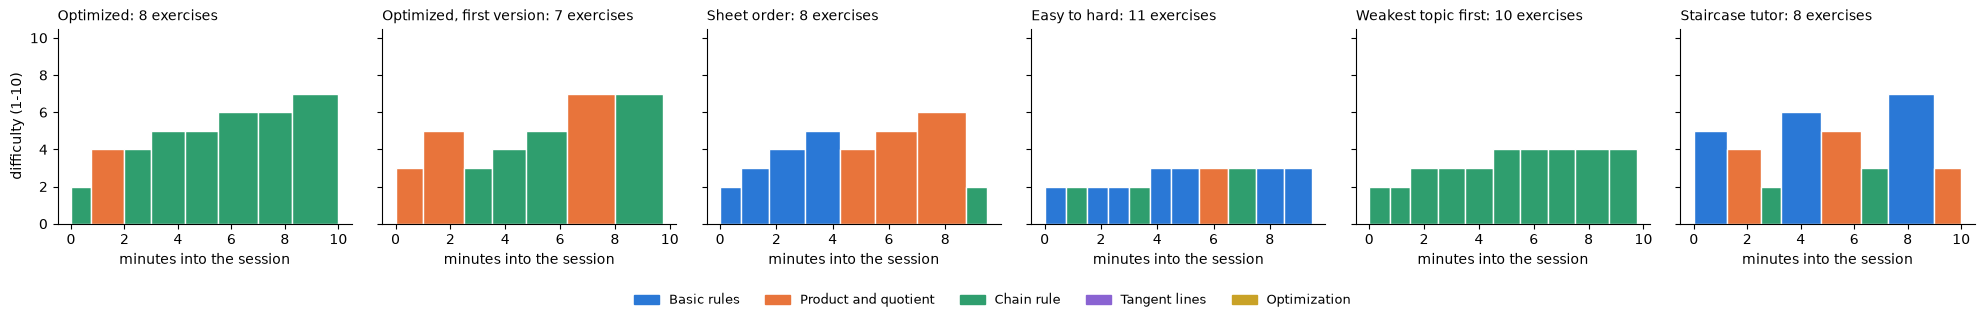

In [7]:
COL = {'basic': '#2a78d6', 'pq': '#e8743b', 'chain': '#2f9e6e', 'tangent': '#8a63d2', 'optim': '#c9a227'}

def plot_plan(ax, order, title, minutes=None):
    """Difficulty (bar height) over time (bar width = minutes) for a sequence of exercises, coloured by topic."""
    t0 = 0.0
    for i in order:
        w = bank[i]['min'] if minutes is None else minutes[i]
        ax.bar(t0, bank[i]['d'], width=w, align='edge', color=COL[bank[i]['topic']], edgecolor='white', linewidth=1)
        t0 += w
    ax.set(ylim=(0, 10.5), xlabel='minutes into the session', ylabel='difficulty (1-10)')
    ax.set_title(title, loc='left', fontsize=10, weight='regular')
    ax.spines[['top', 'right']].set_visible(False)

def legend(fig):
    from matplotlib.patches import Patch
    fig.legend(handles=[Patch(color=COL[c], label=NAME[c]) for c in TOPICS], loc='lower center', ncol=5, frameon=False, fontsize=9)

def static_plan(picker, stu, budget, P=PAR):
    """The sequence a policy would produce if every exercise were solved alone in the estimated time (no surprises)."""
    s2 = dict(stu, topics=stu['topics'], speed=1.0)
    hist, remaining, st, order = [], float(budget), dict(P=P), []
    while True:
        st['remaining'] = remaining
        cand = [i for i in range(N) if i not in order and bank[i]['topic'] in stu['topics'] and bank[i]['min'] <= remaining]
        if not cand: break
        i = picker(s2, cand, hist, st)
        if i is None: break
        order.append(i); hist.append((i, 0.9)); remaining -= bank[i]['min']
    return order


# ---- simulated students and policies (all made up) ----
def make_students(n, seed):
    rnd = random.Random(seed); out = []
    for k in range(n):
        topics = rnd.sample(TOPICS, rnd.choice([2, 3, 3, 4]))
        truth = {c: clamp(rnd.gauss(5, 2.0), 0.5, 9.5) for c in topics}
        bias = rnd.gauss(0, 1.5)
        rating = {c: (None if rnd.random() < 0.1 else clamp(round((truth[c] + bias + rnd.gauss(0, 1.0)) * 2) / 2, 0, 10)) for c in topics}
        out.append(dict(id=k, topics=topics, truth=truth, rating=rating, budget=rnd.choice([5, 10, 20]), speed=rnd.uniform(0.5, 1.4),
                        slip=rnd.uniform(0, 0.12), seed=seed * 1000 + k))
    return out

WORLD = 'ramp'

def attempt(stu, T, i):
    """One simulated attempt. The true success chance uses a different slope (1.2) than the planner's model (1.5)."""
    rnd = random.Random(stu['seed'] * 997 + i)           # same dice for every policy: paired comparison
    u1, u2 = rnd.random(), rnd.random()
    c, d = bank[i]['topic'], bank[i]['d']
    a = T[c]
    p = sig((a - d) / 1.2) * (1 - stu['slip'])
    if u1 < p: r = 0.9                                    # solved alone
    elif u2 < 0.45: r = 0.7                               # solved with a hint
    else: r = 0.4                                         # needed the solution
    minutes = bank[i]['min'] * stu['speed'] * (1.0 if r >= 0.9 else 1.3)
    if WORLD == 'ramp':     # learning grows with how far the exercise is above the current level, halved after a failure
        g = clamp((d - a + 2) / 4, 0, 1) * (1.0 if r >= 0.7 else 0.5)
        T[c] = min(10.0, a + 0.2 * g)
    else:                   # 'peak': learning is largest when the chance of success is about one half, longer exercises teach more
        g = math.exp(-0.5 * ((p - 0.5) / 0.25) ** 2) * (bank[i]['min'] / 1.25) ** 0.5
        T[c] = min(10.0, a + 0.15 * g)
    return r, minutes, p


def pick_sheet(stu, cand, hist, st): return min(cand)
def pick_easy_to_hard(stu, cand, hist, st): return min(cand, key=lambda i: (bank[i]['d'], bank[i]['min']))
def pick_weakest_first(stu, cand, hist, st):
    rt = lambda i: 5.0 if stu['rating'].get(bank[i]['topic']) is None else stu['rating'][bank[i]['topic']]
    return min(cand, key=lambda i: (rt(i), bank[i]['d'], i))
def pick_staircase(stu, cand, hist, st):
    """A simple adaptive tutor: one level estimate per topic, up after a clean solve, down after a miss, topics in turn."""
    lvl = st.setdefault('lvl', {c: (5.0 if stu['rating'].get(c) is None else stu['rating'][c]) for c in stu['topics']})
    if hist:
        j, r = hist[-1]; c = bank[j]['topic']; lvl[c] += 1.0 if r >= 0.9 else (0 if r >= 0.7 else -1.0)
    todo = [c for c in stu['topics'] if any(bank[i]['topic'] == c for i in cand)]
    c = todo[len(hist) % len(todo)]
    return min([i for i in cand if bank[i]['topic'] == c], key=lambda i: (abs(bank[i]['d'] - lvl[c]), i))
def pick_optimizer(stu, cand, hist, st):
    res = solve_path(dict(rating=stu['rating'], hist=hist), st['remaining'], stu['topics'], P=st['P'])
    return res['order'][0] if res['order'] else None
def pick_optimizer_old(stu, cand, hist, st):
    return pick_optimizer(stu, cand, hist, dict(st, P=dict(st['P'], K_CAND=12, PER_TOPIC=None)))
POLICIES = {'Optimized (re-planned after each result)': pick_optimizer, 'Optimized, first version (best 12 overall)': pick_optimizer_old, 'Sheet order': pick_sheet, 'Easy to hard': pick_easy_to_hard,
            'Weakest topic first': pick_weakest_first, 'Staircase tutor (adaptive rule)': pick_staircase}



example = dict(topics=TOP3, rating=student['rating'], speed=1.0)
P_FIG = dict(PAR, TIME=1.0, GAP=0.05)
fig, axes = plt.subplots(1, 6, figsize=(20, 3.2), sharey=True)
plans = {}
for name, f in POLICIES.items():                           # every answer is assumed clean; the optimized designs are re-planned after each one
    plans[name.split(' (')[0]] = static_plan(f, example, 10, P=P_FIG)
for ax, (name, order) in zip(axes, plans.items()):
    plot_plan(ax, order, f"{name}: {len(order)} exercises")
for ax in axes[1:]: ax.set_ylabel('')
legend(fig); plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()


**Reading the figure.** Bar height is the exercise's difficulty and width its time, so the path reads left to right. In all panels every answer is assumed clean, and the two optimized designs are re-planned after each answer, so their paths show the rising level (the 8 exercises of the first panel differ from the 9 of section 5, which is the plan before any answer). The optimized path starts at difficulty 2 in the weakest topic, goes to product and quotient, and returns to the chain rule at difficulty 4 to 7 as the modelled level rises. *Sheet order* mixes topics and difficulty as the sheet does. *Easy to hard* stays at difficulty 2 to 3 for the whole session (11 exercises), whatever the student's ratings are. *Weakest topic first* stays in the chain rule and rises only to 4. The *staircase* adapts to results but has no budget or similarity logic. The first version of our design behaves similarly, but its pool is less balanced (section 7.3).

### How do they perform? A simulation
A solver always returns an answer, so we need evidence that the optimization is worth it. We simulate students who differ from the planner's assumptions on purpose. Each simulated student has a **true ability** in every topic that the planner never sees. The student's **self-rating** is the true ability plus a random error: a bias shared by all topics (about 1.5 points, a student who rates too high or too low everywhere) and a smaller error per topic (about 1 point), rounded to half points, and 10% of the ratings are missing. We do this because real self-assessments are rarely exact. If the ratings were exact, a rule that only looks at the ratings would be close to optimal and the test would say nothing about the use of results. The size of the error is **our assumption**: we have no data on how wrong students' self-ratings are. The students also slip, are faster or slower than the estimates, and the *true* chance of success has a different slope (1.2) than the planner's model (1.5). We use two assumed learning rules, because we do not know how people really learn: in **ramp** the gain grows with how far the exercise is above the current level, in **peak** the gain is largest when the chance of success is about one half and longer exercises teach more. The measure is the mean true ability gain per topic. In each world the same simulated dice are used for every design (a paired comparison), and the optimized design is re-planned after every result, as in our app.

**These are our own constructions. The "peak" world is close to what the optimizer assumes, so a win there is partly by construction.**

In [8]:
def run_session(stu, picker, P=PAR):
    T = dict(stu['truth']); T0 = dict(T)
    remaining = float(stu['budget']); hist, st, minutes, good = [], dict(P=P), 0.0, 0.0
    while True:
        st['remaining'] = remaining
        done = {j for j, r in hist}
        cand = [i for i in range(N) if i not in done and bank[i]['topic'] in stu['topics'] and bank[i]['min'] * stu['speed'] <= remaining]
        if not cand: break
        i = picker(stu, cand, hist, st)
        if i is None: break
        a0 = T[bank[i]['topic']]
        r, mins, p = attempt(stu, T, i)
        hist.append((i, r)); remaining -= mins; minutes += mins
        if 0.4 <= p <= 0.9: good += mins
    gain = float(np.mean([T[c] - T0[c] for c in stu['topics']]))
    return dict(gain=gain, n=len(hist), minutes=minutes, productive=good / minutes if minutes else 0.0)

In [9]:
import time
P_SIM = dict(PAR, TIME=1.0, GAP=0.05)                      # shorter solves, because one session needs many
students = make_students(20, seed=3)
results = {}
t0 = time.time()
for world in ('ramp', 'peak'):
    WORLD = world
    for name, f in POLICIES.items():
        results[world, name] = [run_session(s, f, P_SIM) for s in students]
print(f"{len(students)} students x 2 worlds x {len(POLICIES)} designs in {time.time()-t0:.0f} s")
print(f"{'':<42} {'ramp world':>16} {'peak world':>16}   exercises  chance in 0.4-0.9")
for name in POLICIES:
    row = f"{name:<42}"
    for world in ('ramp', 'peak'):
        g = [r['gain'] for r in results[world, name]]
        row += f" {np.mean(g):>9.3f} ±{np.std(g)/len(g)**.5:.3f}"
    r_ = results['ramp', name]
    row += f"   {np.mean([r['n'] for r in r_]):>8.1f}  {np.mean([r['productive'] for r in r_]):>10.0%}"
    print(row)

20 students x 2 worlds x 6 designs in 160 s
                                                 ramp world       peak world   exercises  chance in 0.4-0.9
Optimized (re-planned after each result)       0.234 ±0.021     0.260 ±0.031        7.1         43%
Optimized, first version (best 12 overall)     0.216 ±0.023     0.259 ±0.033        7.2         49%
Sheet order                                    0.115 ±0.017     0.225 ±0.024        8.0         64%
Easy to hard                                   0.083 ±0.020     0.214 ±0.020       12.4         60%
Weakest topic first                            0.199 ±0.035     0.280 ±0.033       10.2         65%
Staircase tutor (adaptive rule)                0.184 ±0.020     0.260 ±0.030        7.0         54%


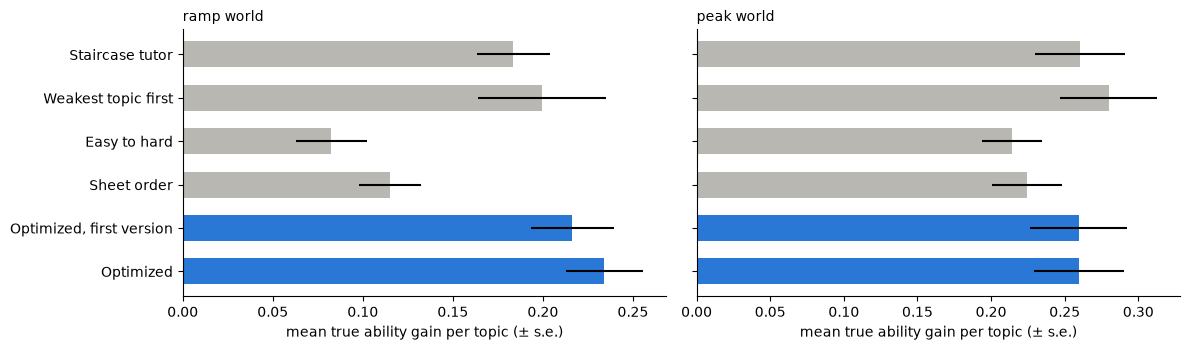

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
names = list(POLICIES)
short = [n.split(' (')[0] for n in names]
for ax, world in zip(axes, ('ramp', 'peak')):
    means = [np.mean([r['gain'] for r in results[world, n]]) for n in names]
    errs = [np.std([r['gain'] for r in results[world, n]]) / len(students) ** .5 for n in names]
    ax.barh(range(len(names)), means, xerr=errs, color=['#2a78d6', '#2a78d6'] + ['#b8b7b2'] * 4, height=.6)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(short); ax.invert_yaxis()
    ax.set_title(f"{world} world", loc='left', fontsize=10, weight='regular'); ax.set_xlabel('mean true ability gain per topic (± s.e.)')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**What the simulation shows.** Read the table and the figure first. In the **ramp world** the optimized design (0.23) is ahead of every simple design (0.08 to 0.20). The difference to *sheet order* and *easy to hard* is several standard errors. The difference to *weakest topic first* and to the *staircase tutor* is small compared with the standard errors (20 students). The second version of the optimized design is slightly ahead of the first (0.23 against 0.22), within the noise. In the **peak world**, which is closest to what the optimizer assumes, all designs are within noise of each other (0.21 to 0.28). Two further observations: the optimized design completes fewer exercises (about 7 against 10 to 12), because it prefers longer, more valuable ones, and it spends a smaller share of the time on exercises in the 40 to 90% success band (43% against 54 to 65%), because its model of the student is wrong for the simulated students by construction.

The optimization is clearly better than rules that ignore the student's ratings and results. The justification for the design is that it is principled (ratings, results, similarity and budget together, with no hand-written ramp rule) and that it responds to the parameters in section 7. The real test is Milestone 4.

### What the rules do not consider
The ability gain above does not measure everything a plan should do. The simple rules ignore near-duplicate exercises, the source of an exercise, and the time left. Here we measure the *first plan* each design gives to 30 simulated students (3 to 5 topics, 5, 10 or 20 minutes; every answer assumed clean for the rules, the optimized design solved once). The measures are: **near-duplicate pairs** in the plan (two exercises with similarity above 0.6, a repeat of the same skill), the **share of generated exercises** (not from the student's course), the **share of the time budget used**, and the **share of the chosen topics covered**.

In [11]:
students30 = make_students(30, seed=5)
designs = {'Optimized': None, 'Sheet order': pick_sheet, 'Easy to hard': pick_easy_to_hard,
           'Weakest topic first': pick_weakest_first, 'Staircase tutor': pick_staircase}
P_EXP = dict(PAR, TIME=2.0, GAP=0.03)
measures = {name: [] for name in designs}
for stu in students30:
    ex = dict(topics=stu['topics'], rating=stu['rating'], speed=1.0)
    for name, f in designs.items():
        if f is None:
            order = solve_path(dict(rating=stu['rating'], hist=[]), stu['budget'], stu['topics'], P=P_EXP)['order']
        else:
            order = static_plan(f, ex, stu['budget'])
        measures[name].append((sum(1 for a, b in itertools.combinations(order, 2) if SIM[a][b] > 0.6),
                               np.mean([bank[i]['src'] == 'ai' for i in order]) if order else 0.0,
                               sum(bank[i]['min'] for i in order) / stu['budget'],
                               len({bank[i]['topic'] for i in order}) / len(stu['topics']), len(order)))
print(f"{'design':<22}{'near-duplicate pairs':>22}{'generated':>11}{'time used':>11}{'topics covered':>16}{'exercises':>11}")
for name, m in measures.items():
    a = np.mean(m, axis=0)
    print(f"{name:<22}{a[0]:>22.1f}{a[1]:>11.0%}{a[2]:>11.0%}{a[3]:>16.0%}{a[4]:>11.1f}")

design                  near-duplicate pairs  generated  time used  topics covered  exercises
Optimized                                0.4        33%        86%             81%        6.9
Sheet order                              3.8        28%        97%             75%        9.2
Easy to hard                             4.8         7%        94%             90%       12.3
Weakest topic first                      6.1        21%        97%             44%       10.3
Staircase tutor                          1.4        40%        98%             98%        7.6


The clear difference is that the optimized plans almost never repeat the same skill (0.4 near-duplicate pairs per plan against 1.4 to 6.1), because the objective penalizes similarity and the rules do not look at it. On the other measures the optimized design is not ahead: it uses 86% of the time budget (94 to 98% for the rules), because its plan is limited by the time limit and the candidate pool, and it uses a larger share of generated exercises than *easy to hard* and *weakest topic first* (33% against 7% and 21%). These are the trade-offs of the objective, and the weights that set them ($\lambda_{\text{gen}}$, $\lambda_{\text{red}}$) are our assumptions.

# 7. What-if analysis
***
We change one important parameter at a time, solve again, and look at how the design changes. All solves use the settings of our app unless said otherwise.

### 7.1 The time budget (5, 10 and 20 minutes)
The time budget is the parameter the student sets in our app.

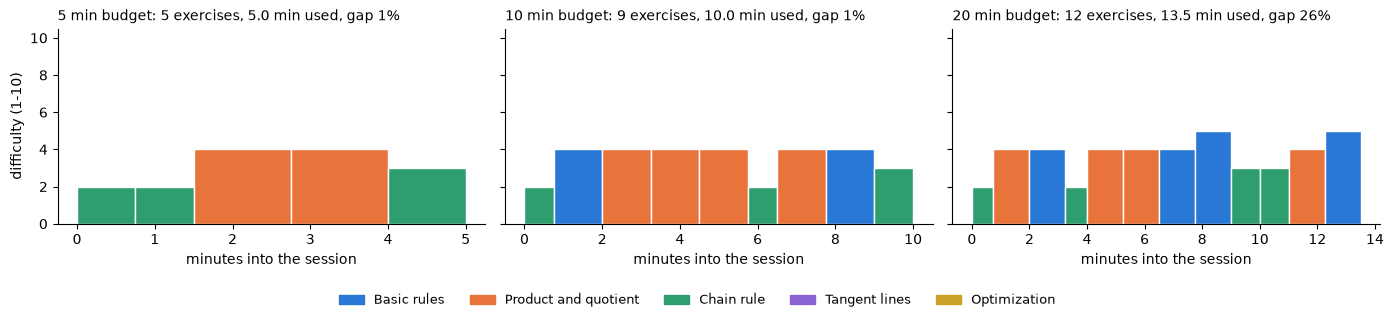

 5 min: optimal    Product and quotient 2, Chain rule 3; mean difficulty 3.0
10 min: optimal    Basic rules 2, Product and quotient 4, Chain rule 3; mean difficulty 3.4
20 min: time limit Basic rules 4, Product and quotient 4, Chain rule 4; mean difficulty 3.7


In [12]:
P_WI = dict(PAR, GAP=0.01, TIME=12.0)
what = {B: solve_path(student, B, TOP3, P=P_WI) for B in (5, 10, 20)}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, B in zip(axes, what):
    r = what[B]; used = sum(bank[i]['min'] for i in r['order'])
    plot_plan(ax, r['order'], f"{B} min budget: {len(r['order'])} exercises, {used:.1f} min used, gap {r['gap']:.0%}")
for ax in axes[1:]: ax.set_ylabel('')
legend(fig); plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()
for B, r in what.items():
    tops = {c: sum(bank[i]['topic'] == c for i in r['order']) for c in TOPICS}
    print(f"{B:>2} min: {r['status']:<10} " + ", ".join(f"{NAME[c]} {n}" for c, n in tops.items() if n) + f"; mean difficulty {np.mean([bank[i]['d'] for i in r['order']]):.1f}")

The number of exercises grows with the budget (5, 9 and 12), the plan covers more topics (two topics with 5 minutes, three with 10 and 20), and the mean difficulty rises from 3.0 to 3.7 because the modelled level rises along a longer path. The plans for 5 and 10 minutes are proven optimal. For 20 minutes the plan uses only 13.5 minutes, because with three topics the candidate pool has 12 exercises, and the solver stops at the time limit (the gap is shown in the figure). In use the plan is recomputed after every answer, so the rest of the time is filled later. This comes from the big-$M$ formulation (section 9), not from the student.

### 7.2 The student's level (all topics rated 3, 5 or 8)

In [13]:
for level in (3, 5, 8):
    s2 = dict(rating={c: level for c in TOPICS}, hist=[])
    r = solve_path(s2, 10, TOPICS, P=P_WI)
    print(f"all topics rated {level}: difficulties {[bank[i]['d'] for i in r['order']]}")

all topics rated 3: difficulties [2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3]


all topics rated 5: difficulties [4, 4, 4, 5, 4, 5, 5, 4]


all topics rated 8: difficulties [6, 7, 7, 7, 7, 6]


A strong student gets harder exercises (6 to 7), a weak one easy ones (2 to 3), and the strong student gets fewer of them (6 against 11), because harder exercises take longer. The design follows the rating, as it must. "Easy to hard" and "sheet order" would give all three students the same path.

### 7.3 The candidate pool: how we improved the first version
Our first version kept the 12 exercises with the highest value overall as candidates, so the integer program stayed small. For the example student this gave a plan of almost only one topic: the 12 best exercises were mostly product and quotient, so chain rule and optimization (the topics rated lowest) never entered the model. The integer program was optimal for what it received, but the pool was biased. In the second version the pool holds **the best 4 exercises of every chosen topic, at most 20 in all**. We compare the two on the same student, scoring both plans with the same objective on a large pool (100 candidates):

first version (best 12 overall)              8 exercises, objective 6.183, 3 topics, 0.7 s


second version (best 4 per topic, max 20)    11 exercises, objective 7.500, 4 topics, 12.0 s


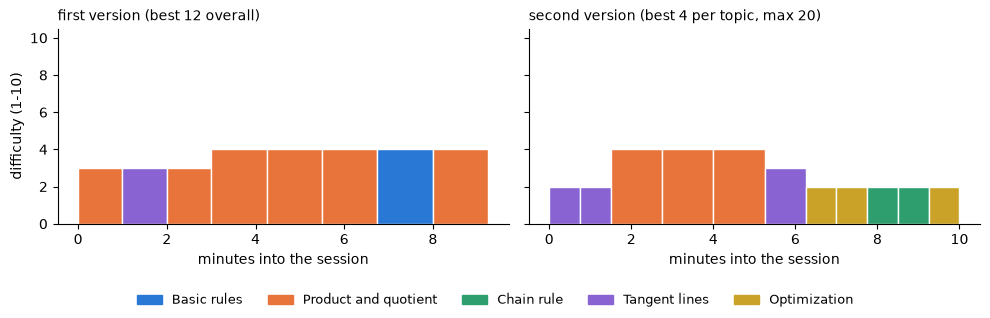

In [14]:
student5 = dict(rating=dict(basic=5, pq=4, chain=2, tangent=3, optim=2), hist=[])      # a student who chose all five topics
D_big = prepare(student5, 10, TOPICS, P=dict(PAR, K_CAND=100, PER_TOPIC=None))
first = dict(P_WI, K_CAND=12, PER_TOPIC=None)               # first version
rows = []
for name, Pp in (('first version (best 12 overall)', first), ('second version (best 4 per topic, max 20)', P_WI)):
    r = solve_path(student5, 10, TOPICS, P=Pp)
    covered = sorted({NAME[bank[i]['topic']] for i in r['order']})
    rows.append((name, r))
    print(f"{name:<44} {len(r['order'])} exercises, objective {sequence_value(r['order'], D_big):.3f}, {len(covered)} topics, {r['runtime']:.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (name, r) in zip(axes, rows):
    plot_plan(ax, r['order'], name)
axes[1].set_ylabel(''); legend(fig); plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

The second version covers four of the five topics (a plan of about 11 exercises cannot touch them all), against three in the first version, and its objective is higher. The cost is a harder solve: with 20 candidates and a time limit of 4 s the solver returns the best plan it found, not a proven optimum (see section 9), and the plan is corrected after every answer anyway.

**On other students.** We repeated the comparison for 14 random students (3 to 5 topics, 5, 10 or 20 minutes):

In [15]:
rng7 = random.Random(11); rows7 = []
for k in range(14):
    tps = rng7.sample(TOPICS, rng7.choice([3, 3, 4, 5]))
    sk = dict(rating={c: rng7.choice([2, 3, 4, 5, 6, 7]) for c in tps}, hist=[]); B = rng7.choice([5, 10, 20])
    Db = prepare(sk, B, tps, P=dict(PAR, K_CAND=100, PER_TOPIC=None))
    row = []
    for Pp in (dict(PAR, K_CAND=12, PER_TOPIC=None), PAR):
        r = solve_path(sk, B, tps, P=Pp)
        row.append((len({bank[i]['topic'] for i in r['order']}), sequence_value(r['order'], Db), r['runtime']))
    rows7.append((len(tps), row))
print(f"topics covered, first version:  {np.mean([r[1][0][0] for r in rows7]):.1f}   second version: {np.mean([r[1][1][0] for r in rows7]):.1f}   (topics chosen: {np.mean([r[0] for r in rows7]):.1f})")
print(f"mean objective, first version:  {np.mean([r[1][0][1] for r in rows7]):.2f}   second version: {np.mean([r[1][1][1] for r in rows7]):.2f}")
print(f"longest solve, second version:  {max(r[1][1][2] for r in rows7):.1f} s (time limit 4 s)")

topics covered, first version:  2.1   second version: 2.8   (topics chosen: 3.5)
mean objective, first version:  4.65   second version: 4.75
longest solve, second version:  4.0 s (time limit 4 s)


# 8. Checks
***
**Gurobi against brute force.** On small instances (6 candidates, 5 minutes) we enumerate every ordered sequence and compare the best value with the integer program's optimum:

In [16]:
rng = random.Random(5)
print('Gurobi optimum vs brute-force optimum on 6 random students:')
for k in range(6):
    stk = dict(rating={c: rng.choice([2, 4, 5, 7]) for c in TOPICS}, hist=[])
    P6 = dict(PAR, K_CAND=6, GAP=1e-6, TIME=30)
    r = solve_path(stk, 5, TOPICS, P=P6)
    bf = brute_force(r['D'], 5, P6)
    print(f"  Gurobi {r['obj']:.5f}   brute force {bf[0]:.5f}   {'equal' if abs(r['obj'] - bf[0]) < 1e-4 else 'DIFFERENT'}")

Gurobi optimum vs brute-force optimum on 6 random students:
  Gurobi 2.34419   brute force 2.34419   equal
  Gurobi 3.06164   brute force 3.06164   equal
  Gurobi 2.10380   brute force 2.10380   equal
  Gurobi 2.26473   brute force 2.26473   equal
  Gurobi 3.03365   brute force 3.03365   equal
  Gurobi 3.02977   brute force 3.02977   equal


**First-order approximation.** The model assumes the value of an exercise changes linearly with the ability gained. We compare the plan's value under that assumption with the value from the exact update (re-evaluating each exercise at the new level) for 12 random students:

In [17]:
errs = []
for k in range(12):
    stk = dict(rating={c: rng.choice([2, 4, 5, 7]) for c in TOPICS}, hist=[])
    Pk = dict(PAR, TIME=2.0); B = rng.choice([5, 10, 20])
    r = solve_path(stk, B, TOPICS, P=Pk)
    if r['order']:
        errs.append(abs(linear_value(r['order'], r['D'], Pk) - exact_value(r['order'], stk, Pk)) / exact_value(r['order'], stk, Pk))
print(f"relative difference between the first-order value and the exact value: mean {np.mean(errs):.1%}, maximum {max(errs):.1%}")

relative difference between the first-order value and the exact value: mean 2.0%, maximum 3.7%


# 9. Limits and what we would improve
***
- **All data are made up.** The bank (difficulty, minutes, tags), the student model constants, the simulated students and both learning rules are assumptions. The simulation can show that the design behaves sensibly, not that it helps real students. Milestone 4 tests that with users.
- **Parameter values are not optimal.** We tuned earlier versions on simulated students and the values did not generalize to fresh ones, so we report them as assumptions and vary the important ones in section 7.
- **The solver is the bottleneck for long budgets.** With the level update (big-$M$ constraints) the model is hard: for 10 and 20 minutes the solver stops at the 4 s limit with a gap above the 3% target, so the plan is a good feasible one, not a proven optimum. Our app therefore re-plans after every answer. The candidate pool (best 4 per topic, at most 20) keeps the model small; a pool chosen by one overall ranking left topics out (section 7.3).
- **Time estimates.** Simulated and real students were faster or slower than the estimates; our app measures the real time and scales the estimates of the next solve.
- **What to record in the A/B test:** success and time per exercise along the session, hint use, and whether students accept the proposed rating changes. These would let us estimate $\eta$, $p^*$ and the time scale instead of assuming them.

### References
- Rasch, G. (1960). *Probabilistic Models for Some Intelligence and Attainment Tests.* Danmarks Paedagogiske Institut, Copenhagen. (The logistic form of $p_e$ in section 3.)
- Wilson, R. C., Shenhav, A., Straccia, M., and Cohen, J. D. (2019). The Eighty Five Percent Rule for optimal learning. *Nature Communications* 10, 4646.
- Bjork, E. L. and Bjork, R. A. (2011). Making things hard on yourself, but in a good way: creating desirable difficulties to enhance learning. In *Psychology and the Real World*, Worth Publishers.